In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Mathematics in Motor Insurance

## Understanding Risk Through Probability, Statistics and Mathematical Models

### Project Overview

Insurance companies need to estimate the risk of future claims in order to calculate appropriate insurance premiums. Mathematics plays an important role in this process because insurance claims are uncertain events, and their frequency and financial impact can vary significantly.

The main goal of this project is to explore how mathematical concepts can be applied to real motor insurance data to understand insurance risk, estimate expected financial losses, and calculate illustrative insurance premiums.

The project focuses on the following mathematical areas:

- **Descriptive Statistics:** Analyzing the distribution of insurance claims and financial losses using mean, median, variance, standard deviation, and other statistical measures.
- **Probability Theory:** Calculating the probability of insurance claims, exploring conditional probabilities, and examining probability distributions.
- **Mathematical Functions:** Investigating how insurance risk changes with driver age and vehicle age using mathematical relationships and functions.
- **Correlation Analysis:** Measuring relationships between driver characteristics, vehicle characteristics, claim frequency, and financial losses.
- **Expected Value and Mathematical Modeling:** Using mathematical expectations to estimate future insurance losses and develop a simplified insurance premium calculation model.

### Research Objectives

The project aims to answer the following questions:

1. What is the probability of an insurance claim, and how does it vary across different groups of drivers and vehicles?
2. How are insurance claims and financial losses distributed?
3. What statistical relationships exist between driver age, vehicle age, and insurance risk?
4. How can mathematical functions and probability models describe insurance claim frequency and expected losses?
5. How can these mathematical results be used to calculate illustrative insurance premiums?

### Methodology

Each mathematical area follows the same approach:

**Mathematical Theory → Formulas → Python Implementation → Visualization → Interpretation of Results**

This structure helps explain the mathematical concepts, apply them to real insurance data, and understand the results.

Python and Jupyter Notebook are used for mathematical calculations, statistical analysis, and data visualization.

The objective is not only to analyze insurance data but also to demonstrate how mathematics can be applied to a real-world problem.

## 1. How Do Vehicle Characteristics Affect Insurance Premiums?

Insurance premiums can depend on several vehicle characteristics, such as engine power, vehicle value, and weight.

In this section, we will investigate whether these characteristics can be used to estimate insurance premiums using a simple mathematical model.

We will compare the estimated premiums with the actual premiums in our dataset.

### 1.1 Mathematical Model

We will use multiple linear regression to estimate insurance premiums based on three vehicle characteristics.

The formula is:

$$
\hat{P} = b_0 + b_1x_1 + b_2x_2 + b_3x_3
$$

where:

- $\hat{P}$ — estimated insurance premium.
- $x_1$ — engine power (`Power`).
- $x_2$ — vehicle value (`Value_vehicle`).
- $x_3$ — vehicle weight (`Weight`).
- $b_0$ — intercept.
- $b_1, b_2, b_3$ — coefficients calculated from our dataset.

We will use linear algebra to calculate the coefficients and compare the estimated premiums with the actual values.

**References:**

- SoftUni, *Linear Algebra – Material Summary
- *Simple and Multiple Linear Regression*

In [83]:
# Select the vehicle characteristics and actual insurance premiums
insurance_data = df[['Power', 'Value_vehicle', 'Weight', 'Premium']].copy()

# Remove rows with missing values
insurance_data = insurance_data.dropna()

# Display the first five records
insurance_data.head()

,Power,Value_vehicle,Weight,Premium
0,80,7068.0,190,222.52
1,80,7068.0,190,213.78
2,80,7068.0,190,214.84
3,80,7068.0,190,216.99
4,80,7068.0,190,213.70


In [86]:
# Create a matrix with the vehicle characteristics
X = insurance_data[['Power', 'Value_vehicle', 'Weight']].to_numpy()

# Create a vector with the actual premiums
y = insurance_data['Premium'].to_numpy()

# Add a column of ones for the intercept
X = np.column_stack((np.ones(len(X)), X))

# Calculate the coefficients using least squares
coefficients = np.linalg.lstsq(X, y, rcond=None)[0]

# Display the calculated coefficients
print(f"b0 = {coefficients[0]:.4f}")
print(f"b1 = {coefficients[1]:.4f}")
print(f"b2 = {coefficients[2]:.4f}")
print(f"b3 = {coefficients[3]:.4f}")

b0 = 167.2974
b1 = 1.0595
b2 = 0.0035
b3 = -0.0121


In [87]:
# Calculate estimated premiums using matrix multiplication
insurance_data['Predicted_Premium'] = X @ coefficients

# Compare actual and estimated premiums
insurance_data[['Premium', 'Predicted_Premium']].head(10).round(2)

,Premium,Predicted_Premium
0,222.52,274.64
1,213.78,274.64
2,214.84,274.64
3,216.99,274.64
4,213.70,274.64
5,215.83,274.64
6,380.20,300.40
7,393.50,300.40
8,393.50,300.40
9,395.47,300.40


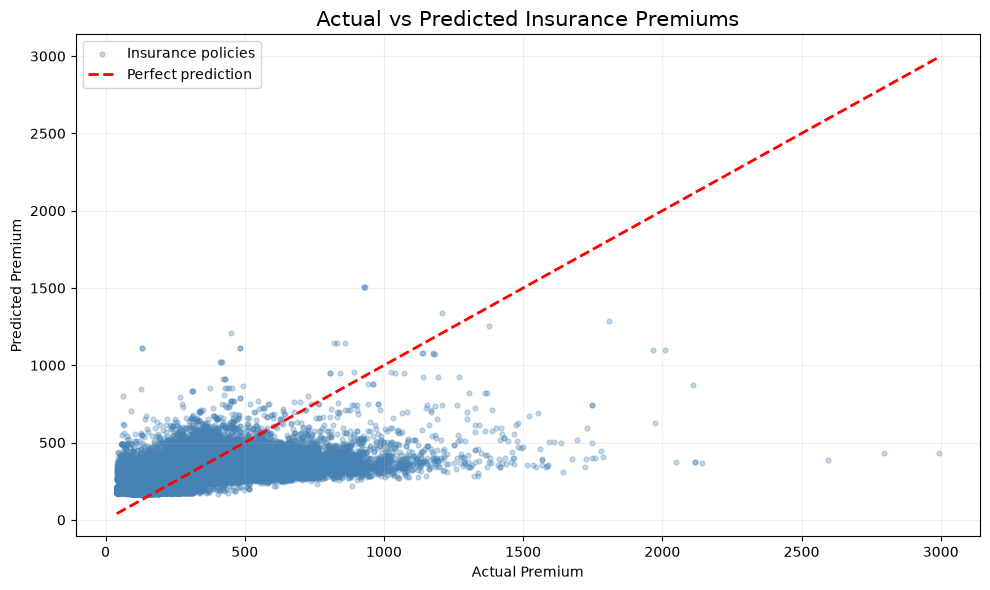

In [88]:
import matplotlib.pyplot as plt

# Compare actual and predicted insurance premiums
plt.figure(figsize=(10, 6))

plt.scatter(
    insurance_data['Premium'],
    insurance_data['Predicted_Premium'],
    alpha=0.3,
    s=12,
    color='steelblue',
    label='Insurance policies'
)

# Draw the line representing perfect predictions
min_val = min(insurance_data['Premium'].min(), insurance_data['Predicted_Premium'].min())
max_val = max(insurance_data['Premium'].max(), insurance_data['Predicted_Premium'].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2,
    label='Perfect prediction'
)

plt.title('Actual vs Predicted Insurance Premiums', fontsize=15)
plt.xlabel('Actual Premium')
plt.ylabel('Predicted Premium')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 1.2 Interpretation of Results

The graph compares actual insurance premiums with the premiums calculated by our model.

Blue dots represent individual insurance records.

Red dashed line represents perfect predictions, where the estimated premium equals the actual premium.

Dots above the line indicate overestimated premiums.

Dots below the line indicate underestimated premiums.

Observations:

The model tends to overestimate lower premiums and underestimate higher premiums. Most predicted values are concentrated in a narrow range, while actual premiums vary significantly.

Conclusion:

Engine power, vehicle value, and weight are not enough to accurately predict all insurance premiums. Other factors may also influence the premium.

This analysis shows both the practical application of linear algebra and the limitations of our simple regression model.

### 1.3 Measuring Prediction Errors

To measure how accurate our model is, we will calculate the Mean Absolute Error (MAE).

The formula is:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|P_i-\hat{P}_i|
$$

where:

- $P_i$ — actual insurance premium.
- $\hat{P}_i$ — predicted insurance premium.
- $n$ — total number of insurance records.

MAE shows the average difference between actual and predicted premiums. A lower MAE means more accurate predictions.

**Source:** [scikit-learn — Mean Absolute Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html)


In [90]:
# Calculate the absolute difference for each insurance record
absolute_errors = np.abs(
    insurance_data['Premium'] - insurance_data['Predicted_Premium']
)

# Calculate the average prediction error
mae = np.mean(absolute_errors)

print(f"Mean Absolute Error (MAE): {mae:.2f}")

Mean Absolute Error (MAE): 84.28


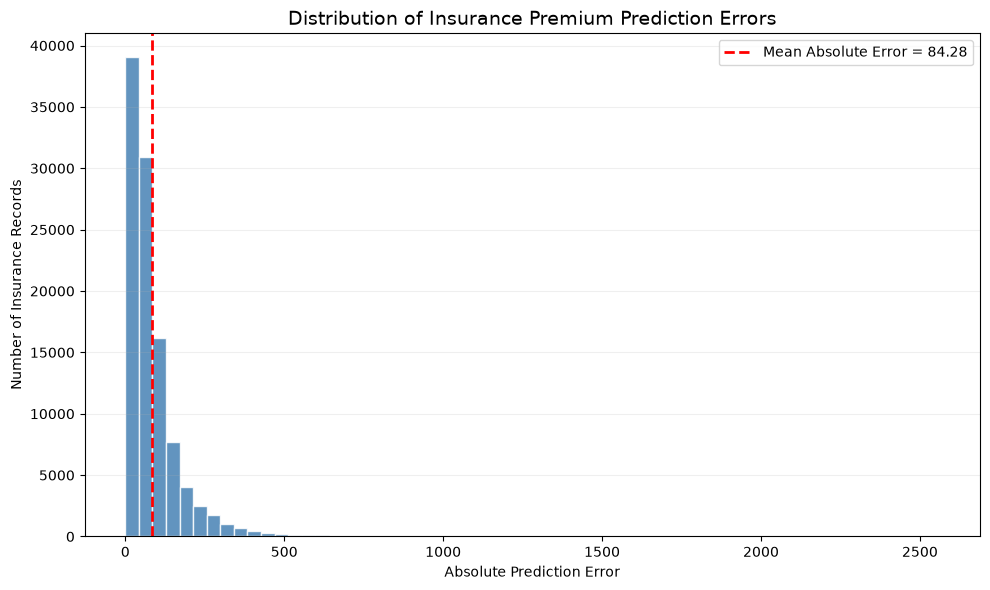

In [91]:
# Calculate absolute prediction errors
absolute_errors = np.abs(
    insurance_data['Premium'] - insurance_data['Predicted_Premium']
)

# Create a histogram of prediction errors
plt.figure(figsize=(10, 6))

plt.hist(
    absolute_errors,
    bins=60,
    color='steelblue',
    edgecolor='white',
    alpha=0.85
)

# Show the average absolute error
plt.axvline(
    mae,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean Absolute Error = {mae:.2f}'
)

plt.title('Distribution of Insurance Premium Prediction Errors', fontsize=14)
plt.xlabel('Absolute Prediction Error')
plt.ylabel('Number of Insurance Records')

plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

### 1.5 Distribution of Prediction Errors

The histogram shows the distribution of absolute prediction errors in our insurance dataset.

- **X-axis (Absolute Prediction Error)** — the difference between the actual and predicted premium, without considering whether the prediction is higher or lower.
- **Y-axis (Number of Insurance Records)** — the number of insurance records in each error range.
- **Blue bars** — show how frequently different prediction errors occur.
- **Red dashed line** — represents the Mean Absolute Error (MAE) of **84.28**.

The histogram helps us understand how prediction errors are distributed across insurance records.

The MAE of 84.28 means that the predicted premiums differ from the actual premiums by an average of 84.28 monetary units.

**Conclusion:**

The histogram provides additional information about the model's accuracy by showing the frequency of different prediction errors, while MAE summarizes these errors in a single value.

## 2. Calculus — How Does Engine Power Affect Insurance Premiums?

In the previous section, we created a linear regression model to estimate insurance premiums using three vehicle characteristics.

Now we will use calculus to investigate how changes in engine power affect the estimated premium.

### 2.1 Partial Derivatives

A partial derivative measures how a function changes when one variable changes while the other variables remain constant.

Our regression model is:

$$
\hat{P} = b_0 + b_1x_1 + b_2x_2 + b_3x_3
$$

To investigate the effect of engine power, we calculate the partial derivative with respect to $x_1$:

$$
\frac{\partial \hat{P}}{\partial x_1} = b_1
$$

From our previous calculations:

$$
\frac{\partial \hat{P}}{\partial x_1} = 1.0595
$$

This means that increasing engine power by one unit increases the estimated insurance premium by approximately **1.06 monetary units**, assuming vehicle value and weight remain constant.

This result describes the behaviour of our mathematical model, not necessarily a causal relationship in real insurance pricing.

**Reference:**
- SoftUni, *Calculus – Material Summary*

### 2.2 - Calculating Premiums for Different Engine Powers
We use our regression model to calculate estimated insurance premiums for engine power values between 50 and 250.

During the calculation:
- Engine power changes from 50 to 250 in steps of 10.
- Vehicle value remains constant at its median value.
- Vehicle weight remains constant at its median value.

According to our partial derivative:

$$
\frac{\partial \hat{P}}{\partial x_1} = 1.0595
$$

For every increase of 10 units in engine power, the estimated premium increases by approximately:

In [94]:
# Generate engine power values from 50 to 250
power_values = np.arange(50, 251, 10)

# Keep vehicle value and weight constant
vehicle_value = insurance_data['Value_vehicle'].median()
vehicle_weight = insurance_data['Weight'].median()

# Calculate predicted premiums for different engine powers
predicted_premiums = (
    coefficients[0]
    + coefficients[1] * power_values
    + coefficients[2] * vehicle_value
    + coefficients[3] * vehicle_weight
)

# Display the first five results
for power, premium in zip(power_values[:5], predicted_premiums[:5]):
    print(f"Power: {power} | Predicted Premium: {premium:.2f}")

Power: 50 | Predicted Premium: 267.67
Power: 60 | Predicted Premium: 278.26
Power: 70 | Predicted Premium: 288.86
Power: 80 | Predicted Premium: 299.45
Power: 90 | Predicted Premium: 310.05


The calculated results confirm our partial derivative.

For every 10 additional units of engine power, the predicted insurance premium increases by approximately 10.60 monetary units.

This demonstrates how derivatives can help us understand changes in insurance premiums.

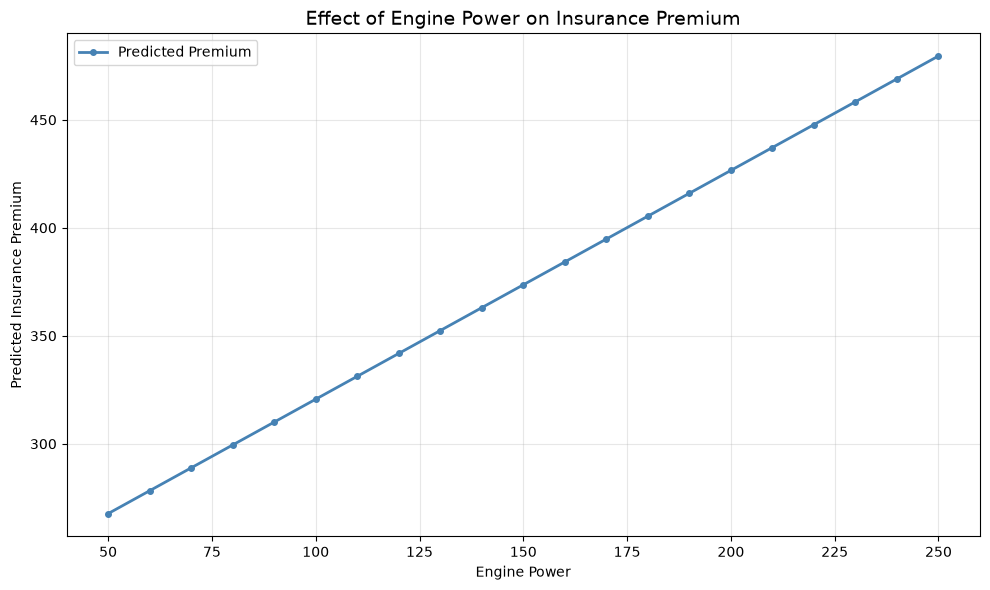

In [95]:
# Plot predicted premiums for different engine power values
plt.figure(figsize=(10, 6))

plt.plot(
    power_values,
    predicted_premiums,
    color='steelblue',
    linewidth=2,
    marker='o',
    markersize=4,
    label='Predicted Premium'
)

plt.title('Effect of Engine Power on Insurance Premium', fontsize=14)
plt.xlabel('Engine Power')
plt.ylabel('Predicted Insurance Premium')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.3 Interpretation of the Graph

The graph shows how the predicted insurance premium changes as engine power increases, while vehicle value and weight remain constant.

We observe a straight, upward-sloping line.

This happens because our regression model is linear, and the partial derivative with respect to engine power is constant:

$$
\frac{\partial \hat{P}}{\partial x_1} = 1.0595
$$

For every 10 additional units of engine power, the predicted premium increases by approximately 10.60 monetary units.

Conclusion:

The graph demonstrates how partial derivatives can be used to measure changes in predicted insurance premiums.

The relationship is linear because of the mathematical model we selected. Actual insurance premiums may depend on additional factors and may not follow the same pattern.

### 2.4 Definite Integrals — Insurance Premium Analysis

In the previous section, we investigated how engine power affects predicted insurance premiums using partial derivatives.

Now we will use definite integrals to calculate the area under the predicted premium curve.

According to the Calculus lecture, a definite integral can be calculated as the limit of a sum of small areas:

$$
\int_a^b f(x)\,dx =
\lim_{\Delta x \to 0}\sum_{i=1}^{n}f(x_i)\Delta x
$$

where:
- $f(x)$ — the function we are investigating.
- $a$ and $b$ — the lower and upper limits.
- $\Delta x$ — the width of each small interval.
- $n$ — the number of intervals.

We will apply this concept to our regression model:

Our predicted insurance premium function is:

$$
\hat{P}(x) = C + 1.0595x
$$

where:
- $\hat{P}(x)$ — predicted insurance premium.
- $x$ — engine power.
- $1.0595$ — the coefficient calculated in our regression model.
- $C$ — the constant part of the model, which includes the intercept and the effects of vehicle value and weight.

We keep vehicle value and weight constant and investigate only changes in engine power.

We want to calculate the area under the predicted premium curve between engine power values of 50 and 250:

$$
A = \int_{50}^{250}\hat{P}(x)\,dx
$$

where:
- $A$ — the area under the predicted premium curve.
- $50$ — the lower limit of engine power.
- $250$ — the upper limit of engine power.
- $\hat{P}(x)$ — our predicted premium function.

To approximate this integral in Python, we divide the interval into small rectangles and add their areas:

$$
A \approx \sum_{i=1}^{n}\hat{P}(x_i)\Delta x
$$

where:
- $n$ — the number of rectangles.
- $x_i$ — the engine power value used for each rectangle.
- $\hat{P}(x_i)$ — the height of each rectangle (predicted premium).
- $\Delta x$ — the width of each rectangle.

Each rectangle has an area of:

$$
S_i = \hat{P}(x_i)\Delta x
$$

By adding the areas of all rectangles, we approximate the definite integral.

As the rectangles become narrower, the approximation becomes more accurate.

**Reference:**
- SoftUni, *Calculus – Material Summary

добре, дай ми маркдаун клетката
### 2.5 Interpretation of the Integral Visualization

The graph shows how we can estimate the area under the predicted insurance premium curve using integrals.

- **Blue line** — represents the predicted insurance premium.
- **Light blue area** — shows the area under the curve between engine power values of 50 and 250.
- **Orange rectangles** — are used to calculate the area using intervals of width 10.

We calculate the total area by adding the areas of all rectangles.

Because the function is increasing, the rectangles give us a slightly smaller result than the actual area.

**Conclusion:**

From this analysis, we can see how integrals can be used with our insurance premium model. We also observe that using smaller intervals gives us a more accurate result.

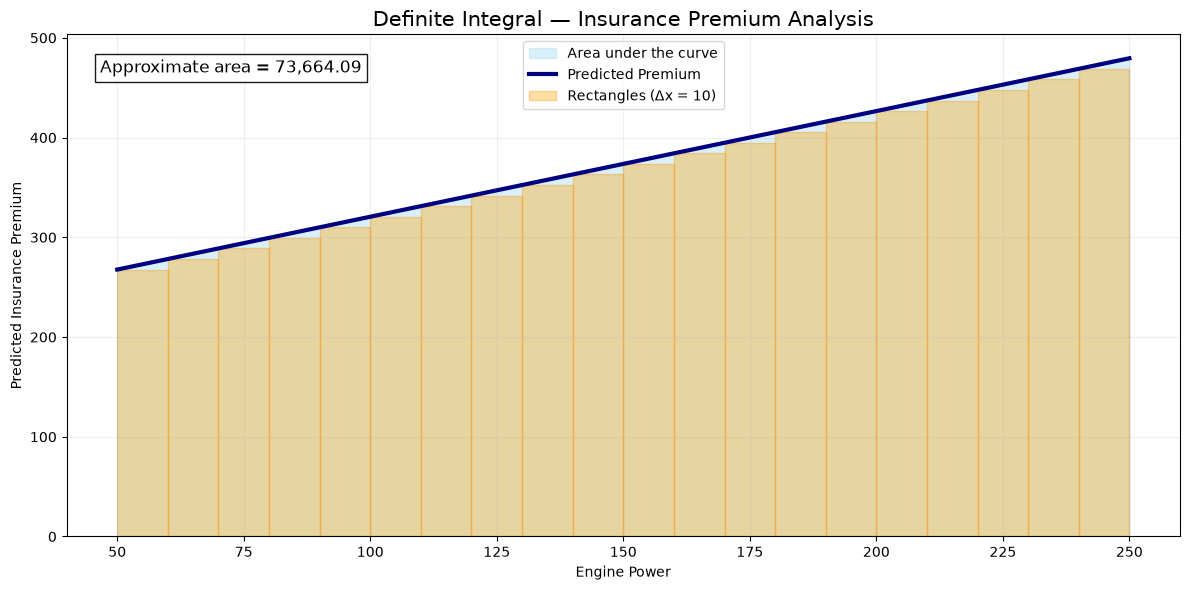

In [97]:

# Define the engine power interval
a, b = 50, 250

# Keep vehicle value and weight constant
vehicle_value = insurance_data['Value_vehicle'].median()
vehicle_weight = insurance_data['Weight'].median()

# Define the constant part of our regression model
C = (
    coefficients[0]
    + coefficients[2] * vehicle_value
    + coefficients[3] * vehicle_weight
)

# Define the predicted premium function
def premium_function(power):
    return C + coefficients[1] * power

# Create points for the smooth line
x = np.linspace(a, b, 500)
y = premium_function(x)

# Create rectangles with a width of 10
dx = 10
rectangle_x = np.arange(a, b, dx)
rectangle_y = premium_function(rectangle_x)

# Approximate the integral using rectangles
area = np.sum(rectangle_y * dx)

# Create the graph
plt.figure(figsize=(12, 6))

# Shade the area under the curve
plt.fill_between(
    x, y,
    color='skyblue',
    alpha=0.3,
    label='Area under the curve'
)

# Draw the rectangles
plt.bar(
    rectangle_x,
    rectangle_y,
    width=dx,
    align='edge',
    color='orange',
    alpha=0.35,
    edgecolor='darkorange',
    label='Rectangles (Δx = 10)'
)

# Draw the predicted premium function
plt.plot(
    x, y,
    color='navy',
    linewidth=3,
    label='Predicted Premium'
)

plt.title('Definite Integral — Insurance Premium Analysis', fontsize=15)
plt.xlabel('Engine Power')
plt.ylabel('Predicted Insurance Premium')

plt.text(
    0.03, 0.95,
    f'Approximate area = {area:,.2f}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.9)
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()